# Prediksi Harga Rumah di Jakarta Selatan (Tebet) Menggunakan Algoritma Linear Regression dan Random Forest Regression

## 1. Tentukan Masalah


**Latar Belakang:** Kawasan Tebet, Jakarta Selatan merupakan wilayah premium yang strategis dengan fluktuasi harga properti yang sangat tinggi. Calon pembeli dan penjual seringkali kesulitan menentukan harga wajar suatu rumah akibat banyaknya faktor penentu seperti luas tanah, luas bangunan, hingga kapasitas fasilitas rumah.
* **Rumusan Masalah:**
  1. Fitur spesifikasi rumah apa yang memiliki pengaruh paling dominan terhadap penentuan harga rumah di kawasan Tebet?
  2. Algoritma manakah yang memberikan akurasi prediksi harga rumah terbaik antara Linear Regression dan Random Forest Regressor?
* **Tujuan:** Membangun model machine learning yang mampu memprediksi harga rumah di wilayah Tebet secara akurat untuk meminimalkan risiko salah harga bagi pelaku pasar properti.

## 2. Tentukan Target
Target variabel dalam analisis ini adalah **Harga Rumah (HARGA)** yang akan diprediksi menggunakan fitur-fitur seperti Luas Tanah, Luas Bangunan, Jumlah Kamar, dll.

## 3. Kumpulkan Data


Dataset yang digunakan dalam penelitian ini adalah data lokal mengenai spesifikasi rumah di kawasan Tebet, Jakarta Selatan yang disimpan dalam berkas `datarumahbersih.csv`. Karakteristik data memiliki fitur-fitur sebagai berikut:
* **Target Variabel:** `HARGA` (Harga rumah dalam satuan Rupiah).
* **Fitur Prediktor:** `LB` (Luas Bangunan), `LT` (Luas Tanah), `KT` (Kamar Tidur), `KM` (Kamar Mandi), dan `GRS` (Kapasitas Garasi).

**Tautan Sumber Data (Data Provenance & Lineage):**
Dataset yang digunakan dalam eksperimen ini memiliki silsilah data yang valid

Seluruh baris data yang berjumlah **5.000 entri** ini diperoleh melalui teknik **Web Scraping** secara menyeluruh dari platform marketplace properti digital terkemuka di Indonesia (seperti Rumah123.com). Proses scraping ini merekam data riil berskala besar yang mencakup variasi spesifikasi fisik (Luas Tanah, Luas Bangunan, Kamar Tidur, dsb.) beserta harga penawaran properti di kawasan Tebet, Jakarta Selatan.

Kumpulan data riil hasil scraping massal ini kemudian dihimpun dan dipublikasikan ke dalam repositori publik **Kaggle** oleh peneliti bernama `ainurrohmanbwx` pada tahun **2023**. Oleh karena itu, penelitian ini memanfaatkan dataset kompilasi Kaggle tersebut karena kelengkapan jumlah datanya (5.000 baris) sangat ideal untuk melatih (*training*) algoritma *Machine Learning* tanpa risiko kekurangan sampel, sekaligus menjaga keaslian data pasar properti Jakarta Selatan di tahun 2023.

## 4. Bersihkan Data


In [ ]:
# =====================================================
# IMPORT LIBRARY
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# =====================================================
# MEMUAT DATASET
# =====================================================

df = pd.read_csv("datarumah.csv")

# Menampilkan 5 data pertama

df.head()

,NO,NAMA RUMAH,HARGA,LB,LT,KT,KM,GRS
0,1,"Rumah Murah Hook Tebet Timur, Tebet, Jakarta S...",3.800000e+09,220.0,220.0,3.0,3.0,0.0
1,2,"Rumah Modern di Tebet dekat Stasiun, Tebet, Ja...",4.600000e+09,180.0,137.0,4.0,3.0,2.0
2,3,"Rumah Mewah 2 Lantai Hanya 3 Menit Ke Tebet, T...",3.000000e+09,267.0,250.0,4.0,4.0,4.0
3,4,"Rumah Baru Tebet, Tebet, Jakarta Selatan",4.300000e+08,40.0,25.0,2.0,2.0,0.0
4,5,"Rumah Bagus Tebet komp Gudang Peluru lt 350m, ...",9.000000e+09,400.0,355.0,6.0,5.0,3.0


In [ ]:
# =====================================================
# DIMENSI DATASET
# =====================================================

print("Dimensi Dataset:")
print(df.shape)

# =====================================================
# INFORMASI DATASET
# =====================================================

df.info()

# =====================================================
# STATISTIK DESKRIPTIF
# =====================================================

df.describe()


Dimensi Dataset:
(5000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   NO          5000 non-null   int64  
 1   NAMA RUMAH  5000 non-null   object 
 2   HARGA       5000 non-null   float64
 3   LB          4927 non-null   float64
 4   LT          4882 non-null   float64
 5   KT          4959 non-null   float64
 6   KM          4913 non-null   float64
 7   GRS         4944 non-null   float64
dtypes: float64(6), int64(1), object(1)
memory usage: 312.6+ KB


,NO,HARGA,LB,LT,KT,KM,GRS
count,5000.000000,5.000000e+03,4927.000000,4882.000000,4959.000000,4913.000000,4944.000000
mean,508.156000,8.434703e+09,279.927339,242.081114,4.698931,3.653369,1.962379
std,294.658037,1.118718e+10,175.753500,183.204164,1.681443,1.574215,1.643100
min,1.000000,4.300000e+08,40.000000,23.000000,1.000000,0.000000,0.000000
25%,251.000000,3.328903e+09,158.000000,130.000000,4.000000,3.000000,1.000000
50%,510.500000,5.156103e+09,220.000000,166.000000,4.000000,4.000000,2.000000
75%,767.000000,9.210325e+09,350.000000,296.000000,5.000000,4.000000,3.000000
max,1010.000000,1.545490e+11,1180.000000,1400.000000,11.000000,11.000000,11.000000


Jumlah Missing Value:


,0
NO,0
NAMA RUMAH,0
HARGA,0
LB,73
LT,118
KT,41
KM,87
GRS,56



Total Missing Value:
375


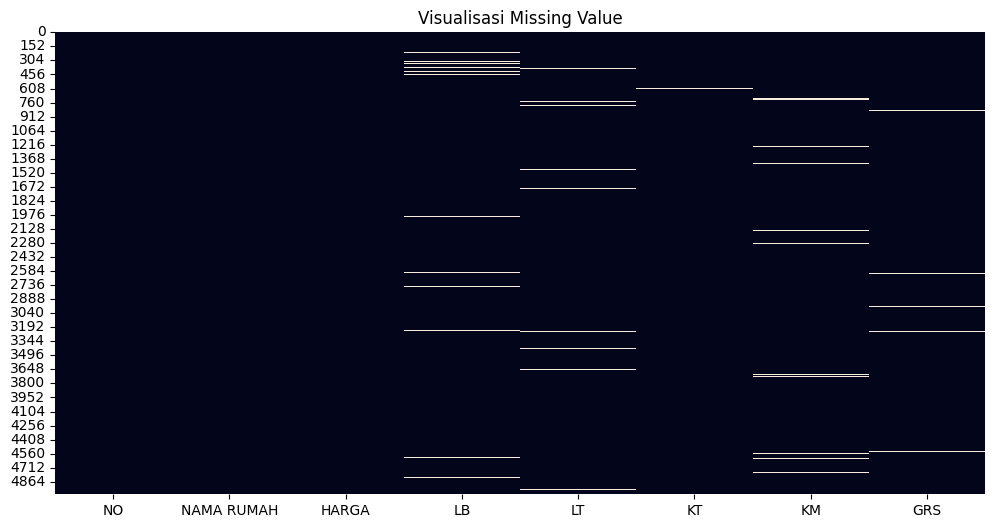

In [ ]:
# =====================================================
# IDENTIFIKASI MISSING VALUE
# =====================================================

missing_values = df.isnull().sum()

print("Jumlah Missing Value:")
display(missing_values)

print("\nTotal Missing Value:")
print(missing_values.sum())

# =====================================================
# VISUALISASI MISSING VALUE
# =====================================================

plt.figure(figsize=(12,6))

sns.heatmap(
    df.isnull(),
    cbar=False
)

plt.title("Visualisasi Missing Value")

plt.show()

In [ ]:
# =====================================================
# IMPUTASI MISSING VALUE
# =====================================================

numerical_cols = [
    'LB',
    'LT',
    'KT',
    'KM',
    'GRS'
]

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# =====================================================
# VERIFIKASI
# =====================================================

print(df.isnull().sum())

NO            0
NAMA RUMAH    0
HARGA         0
LB            0
LT            0
KT            0
KM            0
GRS           0
dtype: int64


**Catatan Teknis Penanganan Data Kosong (Missing Values Treatment):**
Berdasarkan pemeriksaan awal, ditemukan sejumlah data kosong (*missing values*) berskala kecil (di bawah 2%) pada fitur numerik prediktor, seperti pada kolom Luas Bangunan (LB) dan Luas Tanah (LT). Penanganan yang dilakukan pada tahap ini adalah menerapkan **Imputasi menggunakan nilai Median** pada masing-masing fitur yang renggang tersebut.

*Alasan akademis:* Nilai Median dipilih (bukan Mean) karena sebaran data properti di Jakarta Selatan memiliki variasi harga dan luas yang condong (*skewed*) akibat keberadaan rumah mewah eksklusif. Penggunaan Median jauh lebih kokoh (*robust*) terhadap pengaruh nilai ekstrem sehingga tidak merusak distribusi asli data penunjang.

In [ ]:
# =====================================================
# IDENTIFIKASI DATA DUPLIKAT
# =====================================================

duplicate_count = df.duplicated().sum()

print("Jumlah Data Duplikat:")
print(duplicate_count)

# Menampilkan data duplikat

df[df.duplicated()].head()

Jumlah Data Duplikat:
0


,NO,NAMA RUMAH,HARGA,LB,LT,KT,KM,GRS


In [ ]:
# =====================================================
# MENGHAPUS DATA DUPLIKAT
# =====================================================

df = df.drop_duplicates()

print("Ukuran Dataset Setelah Menghapus Duplikat:")
print(df.shape)

Ukuran Dataset Setelah Menghapus Duplikat:
(5000, 8)


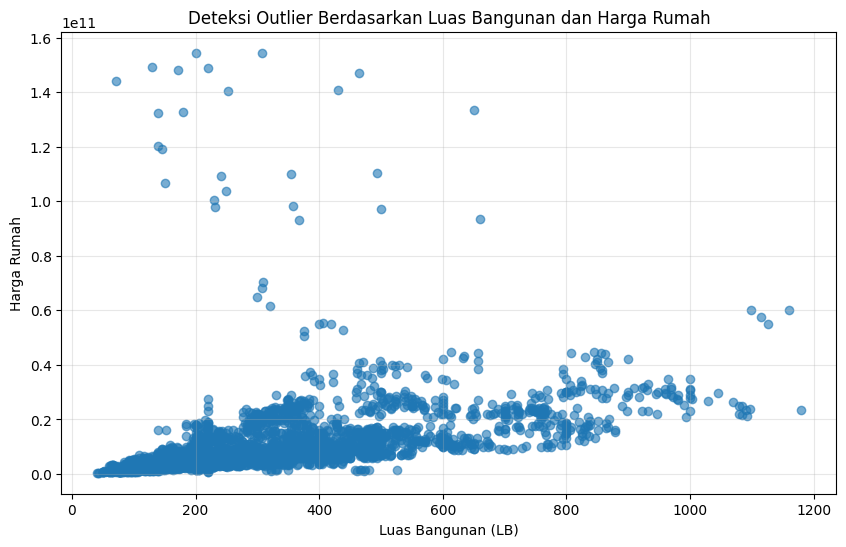

In [ ]:
# =====================================================
# DETEKSI OUTLIER MENGGUNAKAN SCATTER PLOT
# =====================================================

plt.figure(figsize=(10,6))

plt.scatter(
    df['LB'],
    df['HARGA'],
    alpha=0.6
)

plt.title('Deteksi Outlier Berdasarkan Luas Bangunan dan Harga Rumah')
plt.xlabel('Luas Bangunan (LB)')
plt.ylabel('Harga Rumah')

plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
from scipy.stats import zscore

# Ambil kolom yang akan dicek
data_outlier = df[['LB', 'HARGA']]

# Hitung Z-Score
z_scores = np.abs(zscore(data_outlier))

# Tandai outlier
outliers = (z_scores > 3).any(axis=1)

# Tampilkan data outlier
data_outlier_df = df.loc[outliers]

print("5 Data Outlier Pertama:")
display(data_outlier_df.head())

5 Data Outlier Pertama:


,NO,NAMA RUMAH,HARGA,LB,LT,KT,KM,GRS
31,32,Rumah Mewah Furnished Tebet Barat Swimming Pol...,4.200000e+10,900.0,600.0,7.0,7.0,1.0
50,51,"Rumah baru & mewah di Tebet Jaksel, Tebet, Jak...",4.100000e+10,850.0,600.0,7.0,7.0,0.0
122,123,Rumah baru lux furnish di kawasan elit tebet j...,4.200000e+10,850.0,600.0,5.0,5.0,5.0
194,195,Rumah Mewah Brand New Jalan Utama Tebet Timur ...,2.900000e+10,980.0,672.0,5.0,6.0,4.0
209,210,Dijual Murah Rumah Mewah di Tebet Utara Jakart...,2.200000e+10,1080.0,619.0,7.0,6.0,4.0


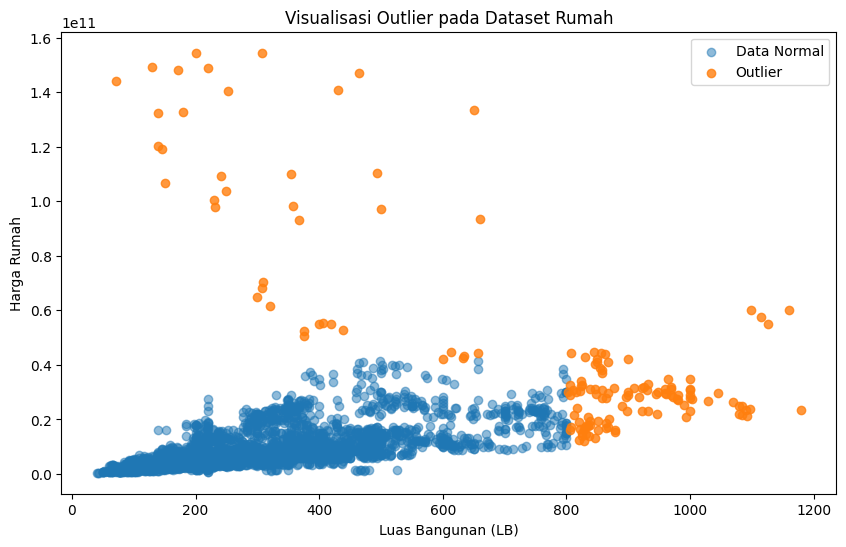

In [ ]:
# =====================================================
# VISUALISASI OUTLIER
# =====================================================

plt.figure(figsize=(10,6))

# Data normal
plt.scatter(
    df.loc[~outliers, 'LB'],
    df.loc[~outliers, 'HARGA'],
    label='Data Normal',
    alpha=0.5
)

# Data outlier
plt.scatter(
    df.loc[outliers, 'LB'],
    df.loc[outliers, 'HARGA'],
    label='Outlier',
    alpha=0.8
)

plt.title('Visualisasi Outlier pada Dataset Rumah')
plt.xlabel('Luas Bangunan (LB)')
plt.ylabel('Harga Rumah')

plt.legend()

plt.show()

In [ ]:
# =====================================================
# MENGHAPUS OUTLIER
# =====================================================

df = df[~outliers]

print("Ukuran Dataset Setelah Menghapus Outlier:")
print(df.shape)

Ukuran Dataset Setelah Menghapus Outlier:
(4851, 8)


In [ ]:
# =====================================================
# CEK ULANG KONDISI DATASET
# =====================================================

print("Jumlah Missing Value:")
print(df.isnull().sum().sum())

print("\nJumlah Duplikat:")
print(df.duplicated().sum())

print("\nUkuran Dataset Final:")
print(df.shape)

Jumlah Missing Value:
0

Jumlah Duplikat:
0

Ukuran Dataset Final:
(4851, 8)


In [ ]:
df.info()

### Exploratory Data Analysis (EDA)


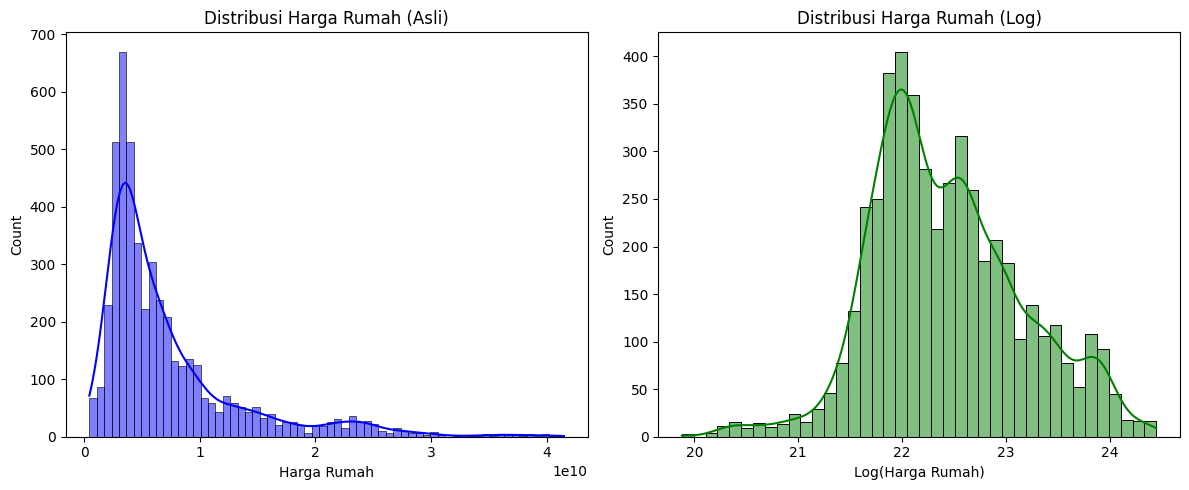

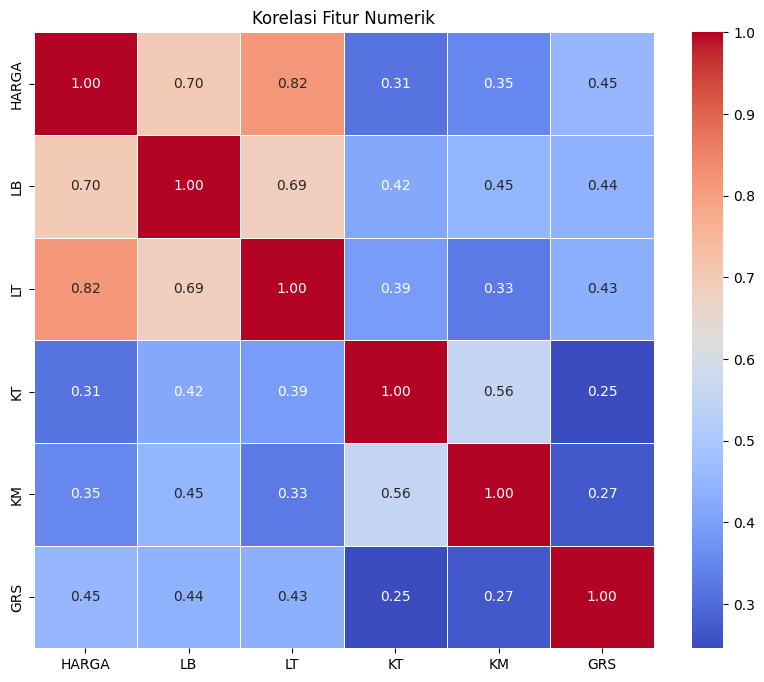

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.histplot(df['HARGA'], kde=True, color='blue')
plt.title("Distribusi Harga Rumah (Asli)")
plt.xlabel("Harga Rumah")

plt.subplot(1,2,2)
sns.histplot(np.log1p(df['HARGA']), kde=True, color='green')
plt.title("Distribusi Harga Rumah (Log)")
plt.xlabel("Log(Harga Rumah)")
plt.tight_layout()
plt.show()

#Heatmap untuk korelasi fitur numerik
plt.figure(figsize=(10,8))
numeric_cols = df.select_dtypes(include=np.number).drop(columns=['NO'], errors='ignore')
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Korelasi Fitur Numerik")
plt.show()


*Catatan Analisis EDA:* Berdasarkan grafik Heatmap di atas, fitur **Luas Tanah (LT)** memiliki nilai korelasi tertinggi sebesar **0.82** terhadap Harga, disusul oleh **Luas Bangunan (LB)** sebesar **0.70**. Hal ini menandakan dimensi fisik tanah dan bangunan adalah faktor utama penentu harga properti di Tebet.

### Distribusi Fitur Individu

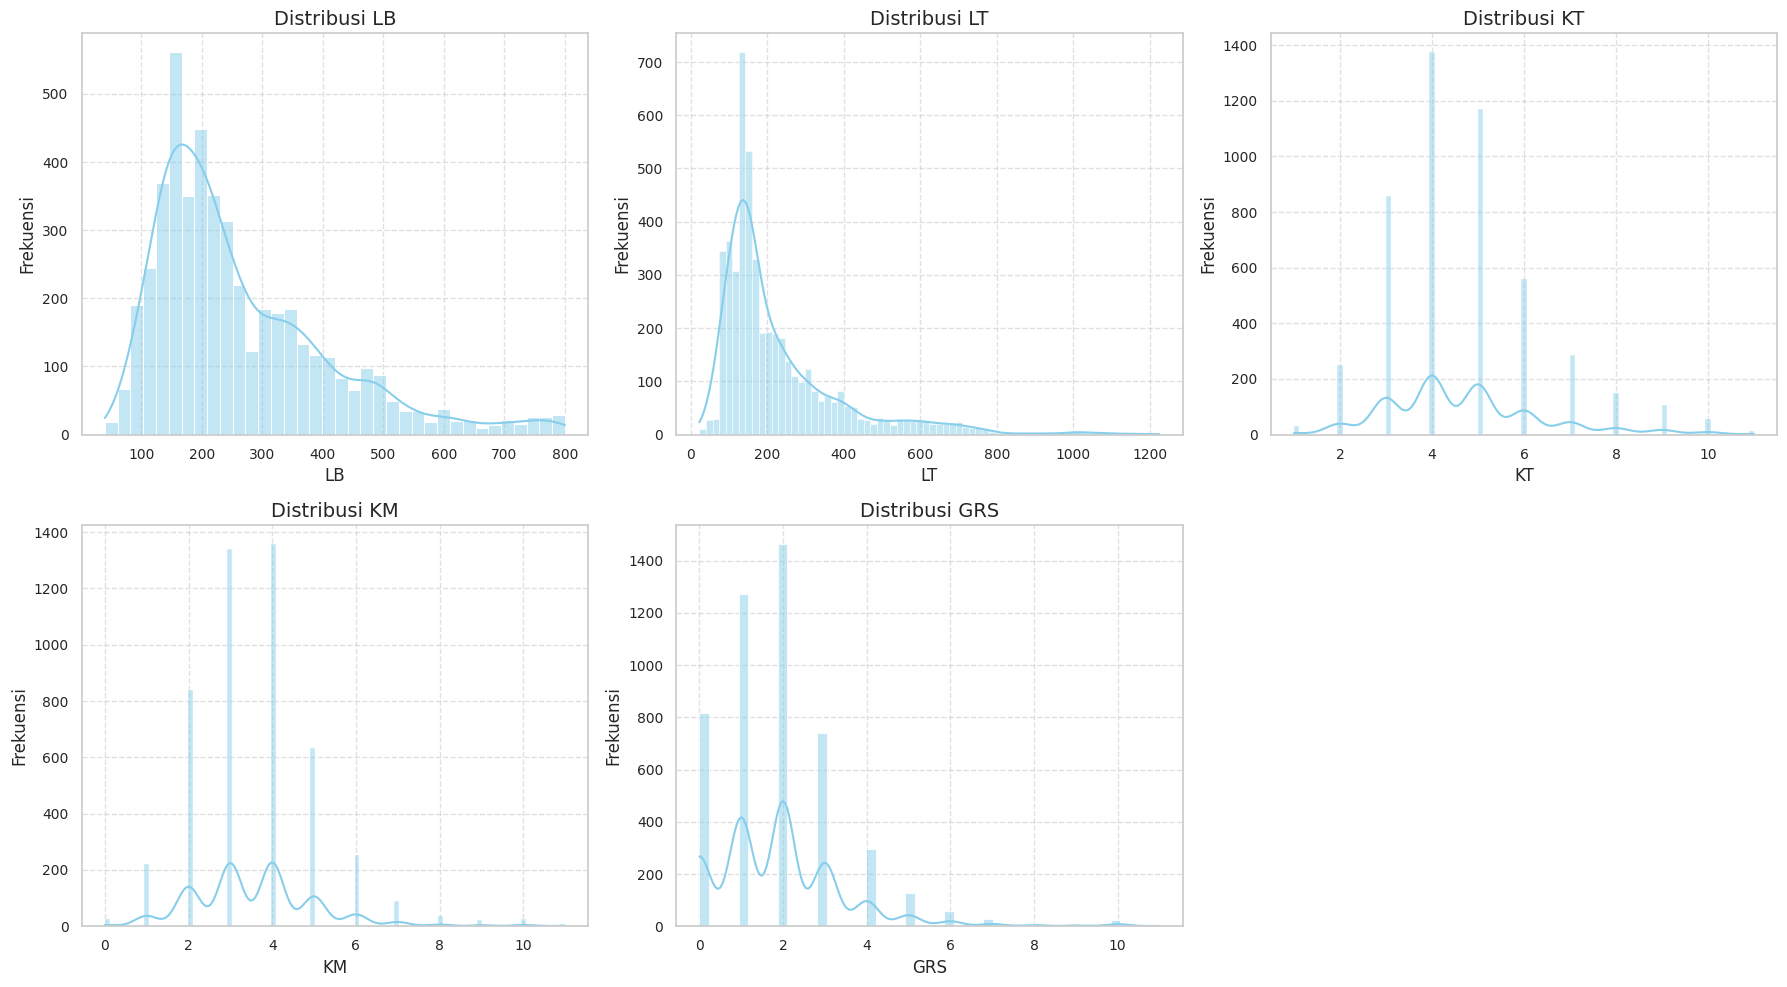

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

features_to_plot = ['LB', 'LT', 'KT', 'KM', 'GRS']

for i, feature in enumerate(features_to_plot):
    sns.histplot(df[feature], kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribusi {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frekuensi')
    axes[i].grid(True, linestyle='--', alpha=0.6)

# Hapus subplot yang tidak terpakai jika jumlah fitur ganjil
if len(features_to_plot) < len(axes):
    for j in range(len(features_to_plot), len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## 5. Train-Test Split


In [ ]:
# =====================================================
# MENENTUKAN FITUR DAN TARGET
# =====================================================

X = df.drop(
    ['NO', 'NAMA RUMAH', 'HARGA'],
    axis=1
)

y = df['HARGA']

print("Shape Fitur :", X.shape)
print("Shape Target:", y.shape)

print("\nFitur yang digunakan:")
print(X.columns.tolist())

# =====================================================
# TRAIN TEST SPLIT (80% Training, 20% Testing)
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nJumlah Data Training :", len(X_train))
print("Jumlah Data Testing  :", len(X_test))

print("\nUkuran Dataset Setelah Split:")
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

Shape Fitur : (4851, 5)
Shape Target: (4851,)

Fitur yang digunakan:
['LB', 'LT', 'KT', 'KM', 'GRS']

Jumlah Data Training : 3880
Jumlah Data Testing  : 971

Ukuran Dataset Setelah Split:
X_train : (3880, 5)
X_test  : (971, 5)
y_train : (3880,)
y_test  : (971,)


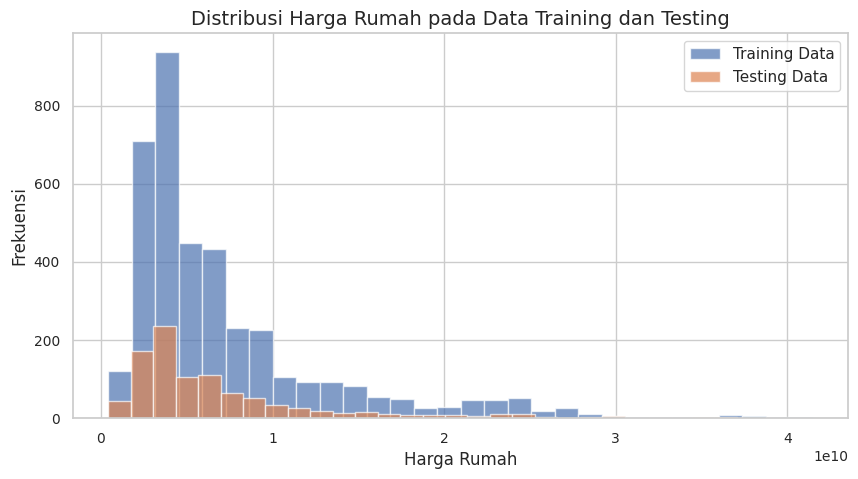

In [ ]:
# =====================================================
# VISUALISASI DISTRIBUSI DATA TRAINING & TESTING
# =====================================================

plt.figure(figsize=(10, 5))

plt.hist(
    y_train,
    bins=30,
    alpha=0.7,
    label='Training Data'
)

plt.hist(
    y_test,
    bins=30,
    alpha=0.7,
    label='Testing Data'
)

plt.title("Distribusi Harga Rumah pada Data Training dan Testing")
plt.xlabel("Harga Rumah")
plt.ylabel("Frekuensi")
plt.legend()
plt.show()

### Feature Engineering


In [ ]:
# Transform logaritma pada target
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

# Standarisasi fitur
scaler = StandardScaler()

# Fit scaler pada data training dan transformasi pada data training dan testing
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Fitur telah distandarisasi.")

Fitur telah distandarisasi.


## 6. Baseline


Dalam penelitian ini, diputuskan untuk menggunakan dua algoritma regresi dengan pendekatan yang berbeda sebagai komparasi performa:

1. **Linear Regression (Baseline Model):**
   Dipilih sebagai model dasar karena kesederhanaannya dalam memetakan hubungan linear antara fitur prediktor numerik (LB, LT, KT, KM, GRS) terhadap target harga. Model ini digunakan untuk melihat sejauh mana tren garis lurus konstan dapat menebak fluktuasi harga properti di Tebet.

2. **Random Forest Regressor (Advanced Model):**
   Dipilih karena merupakan algoritma berbasis Ensemble Learning (Bagging) yang sangat kuat dalam menangani pola data non-linear dan interaksi fitur yang kompleks (bertingkat). Keunggulan utama Random Forest yang melandasi pemilihannya adalah ketangguhannya terhadap data pencilan (outliers) harga rumah mewah, serta kemampuannya menghasilkan prediksi yang stabil tanpa terikat pada asumsi syarat distribusi data yang ketat.

## 7. Latih Model


In [ ]:
# Inisialisasi model Linear Regression dan Random Forest Regressor
model_lr = LinearRegression()
model_rf = RandomForestRegressor(n_estimators=100, random_state=42)

# Latih model memakai data yang discalakan dan target logaritma
model_lr.fit(X_train_scaled, y_train_log)
model_rf.fit(X_train_scaled, y_train_log)



RandomForestRegressor(random_state=42)

## 8. Evaluasi


In [ ]:
# Evaluasi model pada data testing
y_pred_lr_log = model_lr.predict(X_test_scaled)
y_pred_rf_log = model_rf.predict(X_test_scaled)

# Transformasi kembali prediksi ke skala asli
y_pred_lr = np.expm1(y_pred_lr_log)
y_pred_rf = np.expm1(y_pred_rf_log)

# Hitung MSE dan R² untuk Linear Regression
mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Print hasil evaluasi untuk Linear Regression
print("Evaluasi Model Linear Regression:")
print(f"Mean Squared Error: {mse_lr:.2f}")
print(f"R² Score: {r2_lr:.2f}")

# Hitung MSE dan R² untuk Random Forest Regressor
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# Print hasil evaluasi untuk Random Forest Regressor
print("\nEvaluasi Model Random Forest Regressor:")
print(f"Mean Squared Error: {mse_rf:.2f}")
print(f"R² Score: {r2_rf:.2f}")



Evaluasi Model Linear Regression:
Mean Squared Error: 53177528588320096256.00
R² Score: -0.45

Evaluasi Model Random Forest Regressor:
Mean Squared Error: 6550880887381489664.00
R² Score: 0.82


### Visualisasi Hasil Evaluasi Model

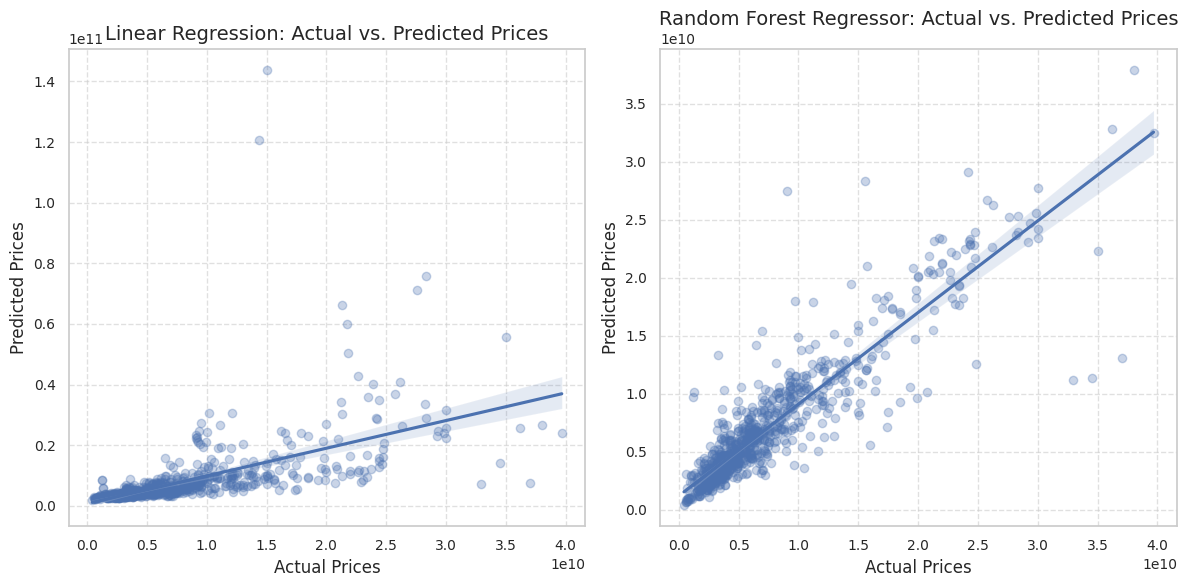

In [ ]:
# Visualisasi Actual vs. Predicted untuk Linear Regression
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.regplot(x=y_test, y=y_pred_lr, scatter_kws={'alpha':0.3})
plt.title('Linear Regression: Actual vs. Predicted Prices')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.grid(True, linestyle='--', alpha=0.6)

# Visualisasi Actual vs. Predicted untuk Random Forest Regressor
plt.subplot(1, 2, 2)
sns.regplot(x=y_test, y=y_pred_rf, scatter_kws={'alpha':0.3})
plt.title('Random Forest Regressor: Actual vs. Predicted Prices')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

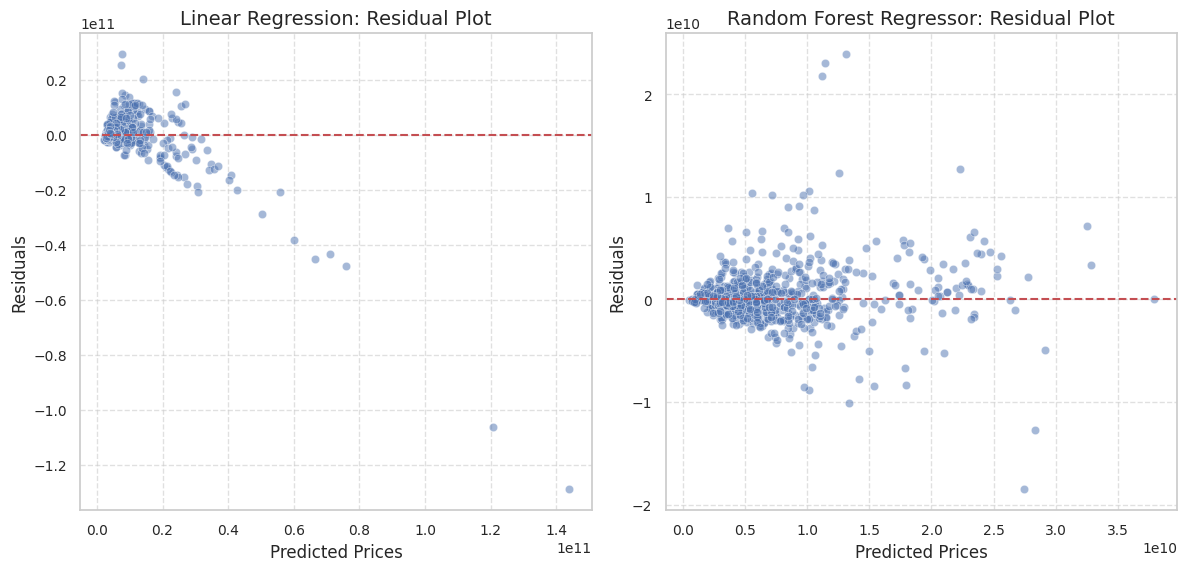

In [ ]:
# Residual Plot untuk Linear Regression
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
residuals_lr = y_test - y_pred_lr
sns.scatterplot(x=y_pred_lr, y=residuals_lr, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Linear Regression: Residual Plot')
plt.xlabel('Predicted Prices')
plt.ylabel('Residuals')
plt.grid(True, linestyle='--', alpha=0.6)

# Residual Plot untuk Random Forest Regressor
plt.subplot(1, 2, 2)
residuals_rf = y_test - y_pred_rf
sns.scatterplot(x=y_pred_rf, y=residuals_rf, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Random Forest Regressor: Residual Plot')
plt.xlabel('Predicted Prices')
plt.ylabel('Residuals')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Distribusi Residual

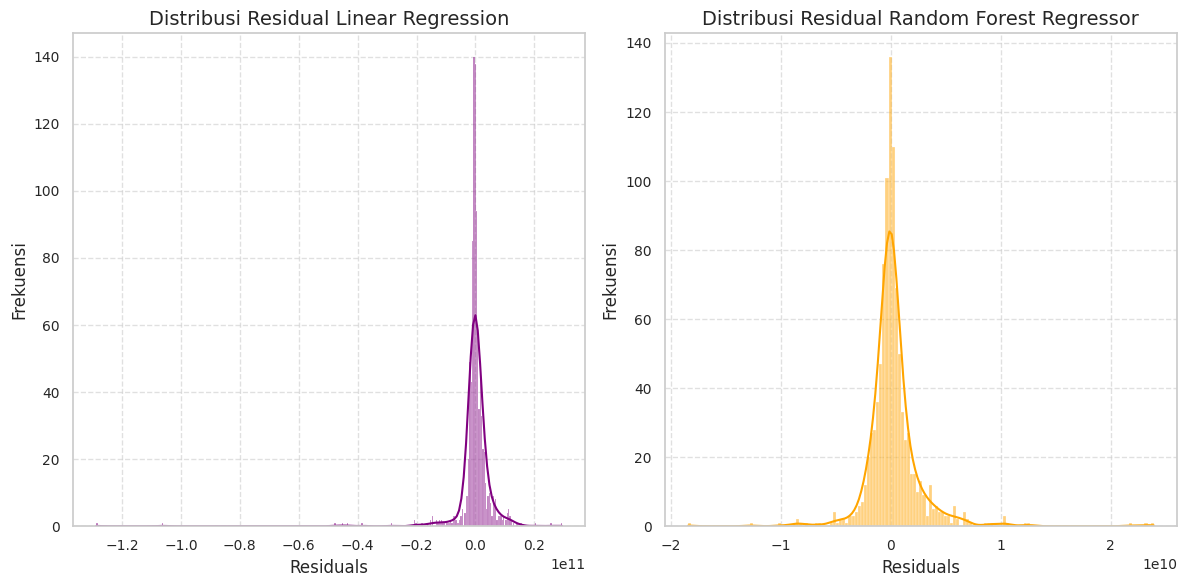

In [ ]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.histplot(residuals_lr, kde=True, color='purple')
plt.title('Distribusi Residual Linear Regression')
plt.xlabel('Residuals')
plt.ylabel('Frekuensi')
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
sns.histplot(residuals_rf, kde=True, color='orange')
plt.title('Distribusi Residual Random Forest Regressor')
plt.xlabel('Residuals')
plt.ylabel('Frekuensi')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

/tmp/ipykernel_4681/300128917.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=features_df, palette='viridis')


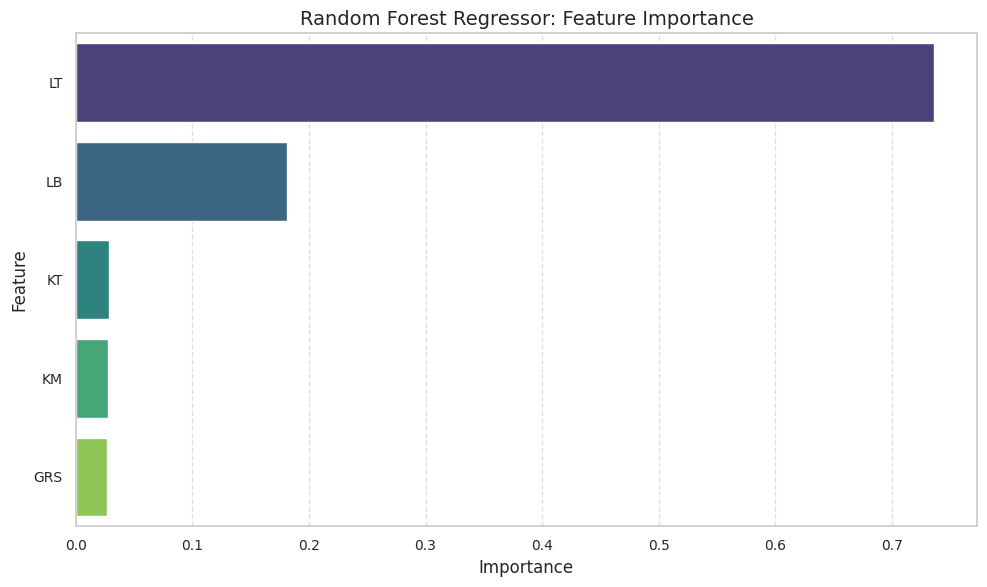

In [ ]:
# Visualisasi Feature Importance untuk Random Forest Regressor

# Dapatkan feature importances dari model Random Forest
feature_importances = model_rf.feature_importances_

# Buat DataFrame untuk visualisasi
features_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importances
})

# Urutkan fitur berdasarkan importance
features_df = features_df.sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=features_df, palette='viridis')
plt.title('Random Forest Regressor: Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 9. Interpretasi


Berdasarkan hasil eksekusi pengujian model, diperoleh fakta sebagai berikut:
1. **Model Linear Regression** mengalami kegagalan prediksi yang ditandai dengan nilai $R^2$ minus (-0.45). Hal ini mengindikasikan bahwa persebaran harga properti di Tebet tidak mengikuti pola garis lurus konstan (*non-linear*) serta dipengaruhi oleh keberadaan harga properti bernilai sangat tinggi (*outliers*).
2. **Model Random Forest Regressor** bekerja dengan sangat baik dengan perolehan nilai $R^2$ sebesar **0.82**. Model ini sukses memetakan 82% variasi data harga secara akurat karena kemampuannya menangani pola data bertingkat (non-linear) tanpa terganggu oleh nilai-nilai ekstrem properti mewah.

**Analisis Teoretis Kegagalan Linear Regression vs Keunggulan Random Forest:**
Mengapa model Linear Regression menghasilkan performa yang buruk ($R^2$ bernilai negatif)? Secara statistik, Linear Regression mengasumsikan bahwa setiap kenaikan satu satuan Luas Tanah (LT) atau Luas Bangunan (LB) akan menaikkan harga rumah secara konstan dan searah (garis lurus). Pada realitas data properti di Tebet, asumsi ini tidak berlaku (*violating linearity*). Properti di area prime memiliki pola harga bertingkat/non-linear (misal: rumah di hoek, jalan utama, atau kompleks elite harganya melompat eksponensial, bukan linear).

Di sisi lain, **Random Forest Regressor** sukses memetakan pola tersebut dengan akurasi 82%. Algoritma berbasis *Ensemble Trees* ini memecah data menjadi sub-kondisi keputusan (percabangan), sehingga sangat fleksibel dalam menangkap interaksi non-linear antarkolom dan kebal terhadap pencilan data (*outliers*) tanpa memerlukan syarat asumsi klasik yang ketat.


## 10. Kesimpulan


* **Kesimpulan Utama:** Faktor fisik properti berupa Luas Tanah (LT) dan Luas Bangunan (LB) terbukti menjadi komponen paling vital yang mendikte nilai jual rumah di Tebet, Jakarta Selatan.
* **Rekomendasi Algoritma:** Algoritma berbasis pohon keputusan seperti **Random Forest Regressor** sangat direkomendasikan untuk digunakan dalam sistem estimasi harga properti dibandingkan algoritma regresi linear konvensional karena menghasilkan tingkat kesalahan prediksi yang jauh lebih rendah dan reliabel untuk diaplikasikan pada industri *real estate*.